# Strategy Economics — Research-Paper-Driven Single-Factor Experiment

This notebook extends the original **fixed train/test experiment** with a minimal LLM research interpreter. It preserves the numerical portfolio optimizer, simulated predictive-information experiments, out-of-sample backtesting and fund-fee valuation.

**Run sequence:** configure paths and factor descriptions → upload/place one PDF → interpret and review its match to an existing exposure column → optimize positive / neutral / negative portfolios → run the original experiments.

**Important limitation:** The original simulated forecast target is **forward oil returns**. The notebook will stop before the Monte Carlo stage if the PDF selects another factor. To run a different factor honestly, replace the forward target with a matching historical factor-return series and use a point-in-time-consistent data pipeline. Static/full-sample factor exposures may also introduce look-ahead bias.

This notebook does not execute a paid API call until you run the research extraction cell.

In [1]:
from pathlib import Path
from dotenv import load_dotenv
import os

load_dotenv(Path.cwd() / ".env")

print("API key available:", bool(os.getenv("OPENAI_API_KEY")))

API key available: True


## 1. Imports

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from lib.optimizer_oos import (
    OptimizerSettings,
    create_portfolio_weights_from_cross_section,
)

from lib.walkforward_oos import (
    load_static_exposures,
    load_universe_prices,
    make_market_rebalance_dates,
    precompute_regime_returns,
    run_oos_backtest_from_precomputed,
)

from lib.config import Paths, BacktestConfig
from lib.data import prepare_forward_target
from lib.signals import simulate_signal, signal_diagnostics
from lib.metrics import performance_metrics

from lib.smart_beta_llm_wrapper import (
    extract_factor_from_pdf,
    build_regime_portfolios,
    make_regime_targets,
)


## 2. Paths

In [3]:
paths = Paths(
    skeleton = Path(r"SampleData\Master-Hist-Skeleton.xlsx"),
    oil_prices=Path(r"SampleData\OilPrices.csv"),
    hist_dir=Path(r"Hist"),
    master=Path(r"SampleData\Master.xlsx"),
    portfolio_dir=Path(r"Portfolios"),
    output_dir=Path(r"Tests_v2_TrainTest"),
)

paths.output_dir.mkdir(parents=True, exist_ok=True)

TRAIN_TEST_CACHE = Path("TrainTestPortfolios")
TRAIN_TEST_CACHE.mkdir(parents=True, exist_ok=True)

## 3. Train/test dates and settings

In [4]:
TRAIN_START = pd.Timestamp("2011-01-01")
TRAIN_END   = pd.Timestamp("2016-12-31")

TEST_START  = pd.Timestamp("2017-01-01")
TEST_END    = pd.Timestamp("2023-01-01")

REBUILD_PORTFOLIOS = True

base_targets = {
    "MKTB": 0.80,
    "CCDB": 0.00,
    "OILP": 0.00,
    "CONS": 0.00,
    "EMPR": 0.00,
}

opt_settings = OptimizerSettings(
    long_allocation=1.0,
    short_allocation=0.3,
    max_weight=0.05,
    precision=1e-4,
    winsor_tail=0.02,
    max_iterations=2000,
    min_assets=25,
)

cfg = BacktestConfig(
    start_date=str(TEST_START.date()),
    end_date=str(TEST_END.date()),
    rebalance_calendar_days=30,
    threshold=0.75,
    positive_beta=0.4,
    negative_beta=-0.20,
    rsq_values=(0, 0.001, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 
                0.06, 0.07, 0.08, 0.09, 0.1, 0.125, 0.15, 
                0.175, 0.2, 0.5, 0.75, 0.95),
    n_runs=100,
    seed=20261003,
    signal_mode="score",
    winsor_tail=0.02,
    annual_rf=0.0175,
)

## 4. Load static factor exposures

In [5]:
factor_cols = list(base_targets.keys())

static_exposures = load_static_exposures(
    master_path=paths.master,
    factors=factor_cols,
)

print(f"Static exposure universe: {len(static_exposures)} securities")
display(static_exposures.head())

Static exposure universe: 406 securities


,MKTB,CCDB,OILP,CONS,EMPR
Symbol,,,,,
A,1.543824,-4.619549,0.002458,-0.633259,-9.665495
AAPL,1.449346,-2.524783,-0.078407,0.536939,5.052891
ABT,0.975286,0.089111,-0.048674,-0.120879,0.989657
ACGL,0.567149,-0.365722,0.023468,-0.283584,-2.859619
ACN,1.210271,-0.266200,-0.012491,-1.290400,-4.749934


## 5. Load security price histories

In [6]:
prices = load_universe_prices(
    hist_dir=paths.hist_dir,
    symbols=static_exposures.index.tolist(),
)

print(f"Price matrix shape: {prices.shape}")
print(f"Available history: {prices.index.min().date()} -> {prices.index.max().date()}")

Price matrix shape: (3588, 406)
Available history: 2010-01-04 -> 2024-04-05


## 6. Build one pre-2017 training cross-section

In [7]:
def build_fixed_training_cross_section(
    prices,
    static_exposures,
    train_start,
    train_end,
    min_observations=252,
    min_coverage=0.70,
):
    # Uses only the fixed training window.
    train_start = pd.Timestamp(train_start).normalize()
    train_end = pd.Timestamp(train_end).normalize()

    window = prices.loc[
        (prices.index >= train_start)
        & (prices.index <= train_end)
    ].copy()

    if window.empty:
        raise ValueError("Training price window is empty.")

    rows = []

    for symbol in static_exposures.index.intersection(window.columns):
        s = window[symbol].dropna()

        if len(s) < min_observations:
            continue

        coverage = len(s) / max(len(window), 1)
        if coverage < min_coverage:
            continue

        first = float(s.iloc[0])
        last = float(s.iloc[-1])

        if (
            not np.isfinite(first)
            or not np.isfinite(last)
            or first <= 0
        ):
            continue

        rows.append({
            "Symbol": symbol,
            "TrainingReturn": last / first - 1.0,
            "TrainingObs": len(s),
            "TrainingCoverage": coverage,
            "TrainingFirstDate": s.index[0],
            "TrainingLastDate": s.index[-1],
        })

    if not rows:
        raise ValueError("No securities meet the training-history requirements.")

    cross_section = pd.DataFrame(rows)

    cross_section = cross_section.join(
        static_exposures,
        on="Symbol",
        how="inner",
    )

    return cross_section.reset_index(drop=True)


training_cross_section = build_fixed_training_cross_section(
    prices=prices,
    static_exposures=static_exposures,
    train_start=TRAIN_START,
    train_end=TRAIN_END,
)

print(f"Training universe: {len(training_cross_section)} securities")
print(
    "Training dates used:",
    training_cross_section["TrainingFirstDate"].min().date(),
    "->",
    training_cross_section["TrainingLastDate"].max().date(),
)

display(training_cross_section.head())

Training universe: 406 securities
Training dates used: 2011-01-03 -> 2016-12-30


,Symbol,TrainingReturn,TrainingObs,TrainingCoverage,TrainingFirstDate,TrainingLastDate,MKTB,CCDB,OILP,CONS,EMPR
0,A,0.600667,1510,1.0,2011-01-03,2016-12-30,1.543824,-4.619549,0.002458,-0.633259,-9.665495
1,AAPL,1.700771,1510,1.0,2011-01-03,2016-12-30,1.449346,-2.524783,-0.078407,0.536939,5.052891
2,ABT,0.951336,1510,1.0,2011-01-03,2016-12-30,0.975286,0.089111,-0.048674,-0.120879,0.989657
3,ACGL,1.925415,1510,1.0,2011-01-03,2016-12-30,0.567149,-0.365722,0.023468,-0.283584,-2.859619
4,ACN,1.753320,1510,1.0,2011-01-03,2016-12-30,1.210271,-0.266200,-0.012491,-1.290400,-4.749934


## 7. Research paper → one existing factor (LLM)

Put your chosen paper at `Research/factor_paper.pdf` and set `RUN_LLM_EXTRACTION = True` below. The agent must select an **exactly compatible** column in `Master.xlsx`; it cannot invent factor exposures or portfolio weights. For offline development, keep `RUN_LLM_EXTRACTION = False` and use the explicit manual `OILP` interpretation. Review the extracted definition and supporting section before proceeding.

In [8]:
from lib.smart_beta_llm_wrapper import FactorInterpretation

PAPER_PATH = Path("Research/Oil_Factor_Mock_Research_Paper.pdf")
RUN_LLM_EXTRACTION = True  # set True to call API; needs OPENAI_API_KEY
LLM_MODEL = "gpt-5.1"

# Replace these descriptions with the ACTUAL definitions used to produce Master.xlsx exposures.
AVAILABLE_FACTORS = {
    "MKTB": "Equity market beta; verify estimation window and market index",
    "CCDB": "Credit spread sensitivity; verify series and transformation",
    "OILP": "Oil price sensitivity; verify oil return series and units",
    "CONS": "Consumption or consumer-conditions sensitivity; verify series",
    "EMPR": "Employment conditions sensitivity; verify series",
}

if RUN_LLM_EXTRACTION:
    if not PAPER_PATH.is_file():
        raise FileNotFoundError(f"Upload the research PDF to {PAPER_PATH.resolve()}")
    interpretation = extract_factor_from_pdf(
        pdf_path=PAPER_PATH,
        available_factors=AVAILABLE_FACTORS,
        model=LLM_MODEL,
    )
else:
    # Offline smoke test only. Not an LLM result or a claim about a paper.
    interpretation = FactorInterpretation(
        paper_title="MANUAL TEST — oil factor (no PDF analyzed)",
        selected_factor="OILP",
        factor_definition="Placeholder: existing OILP exposure in Master.xlsx",
        predicted_return_relation="positive",
        paper_evidence="No paper analyzed: offline integration test",
        cautions=["Manual smoke-test input; verify factor definition before research use."],
        can_implement=True,
    )

print(interpretation.model_dump_json(indent=2))
FACTOR = interpretation.selected_factor
if not interpretation.can_implement or FACTOR == "NONE":
    raise ValueError(f"Paper cannot be implemented with available exposures: {interpretation.cautions}")
if FACTOR not in base_targets or FACTOR not in training_cross_section.columns:
    raise ValueError(f"Selected factor {FACTOR!r} missing from baseline targets or cross-section")
if interpretation.predicted_return_relation == "unclear":
    print(
        "Note: The paper does not establish an unconditional "
        "expected-return premium for this factor. "
        "Proceeding with factor-exposure construction."
    )
print(f"Selected {FACTOR}. Please verify evidence and meaning before running optimization.")

Input tokens: 3,138
Output tokens: 464
Estimated API cost: $0.0086
{
  "paper_title": "Oil-Price Exposure as a Single-Factor Smart-Beta Strategy",
  "selected_factor": "OILP",
  "factor_definition": "Security-level sensitivity of equity returns to oil-price changes, estimated as the coefficient b_i,oil in a regression of each stock’s returns on oil returns and other controls (r_i(t) = a_i + b_i,oil r_oil(t) + G_i X(t) + e_i(t)).",
  "predicted_return_relation": "unclear",
  "paper_evidence": "Section 1 (Economic hypothesis and interpretation, p.1) defines the single factor as oil-price sensitivity OILP and notes that a positive-OILP portfolio has positive beta to oil returns and a negative-OILP portfolio has negative beta. The note explicitly states it \"does not claim that high-OILP equities unconditionally earn higher average returns\" and only proposes an illustrative conditional hypothesis that higher (lower) oil returns favor positive (negative) exposure. Section 11 reiterates tha

## 8. Build or load the three frozen factor-regime portfolios

In [9]:
import json
import hashlib
from dataclasses import asdict

POSITIVE_EXPOSURE = cfg.positive_beta
NEGATIVE_EXPOSURE = cfg.negative_beta
factor_targets = {**base_targets, FACTOR: 0.0}

# Include paper identity, the selected factor, training inputs, and optimizer settings.
# LLM interpretation changes may require REBUILD_PORTFOLIOS=True.
paper_digest = (hashlib.sha256(PAPER_PATH.read_bytes()).hexdigest()[:12]
                if RUN_LLM_EXTRACTION and PAPER_PATH.exists() else "manual")
config_blob = json.dumps({
    "factor": FACTOR,
    "paper_digest": paper_digest,
    "positive": POSITIVE_EXPOSURE,
    "negative": NEGATIVE_EXPOSURE,
    "targets": factor_targets,
    "train_start": str(TRAIN_START.date()),
    "train_end": str(TRAIN_END.date()),
    "optimizer": asdict(opt_settings),
}, sort_keys=True, default=str)
config_digest = hashlib.sha256(config_blob.encode()).hexdigest()[:16]
cache_dir = TRAIN_TEST_CACHE / f"{FACTOR}_{config_digest}"
cache_dir.mkdir(parents=True, exist_ok=True)
portfolio_paths = {r: cache_dir / f"{r}.csv" for r in ("positive", "neutral", "negative")}
diagnostics_path = cache_dir / "diagnostics.csv"

have_cache = all(p.exists() for p in portfolio_paths.values())
if have_cache and not REBUILD_PORTFOLIOS:
    print("Loading cached portfolios:", cache_dir)
    portfolios = {r: pd.read_csv(p) for r, p in portfolio_paths.items()}
    optimizer_diagnostics = (pd.read_csv(diagnostics_path)
                             if diagnostics_path.exists() else pd.DataFrame())
else:
    portfolios, optimizer_diagnostics = build_regime_portfolios(
        interpretation=interpretation,
        cross_section=training_cross_section,
        base_targets=factor_targets,
        positive_exposure=POSITIVE_EXPOSURE,
        negative_exposure=NEGATIVE_EXPOSURE,
        optimizer_function=create_portfolio_weights_from_cross_section,
        optimizer_settings=opt_settings,
    )
    for regime, portfolio in portfolios.items():
        portfolio.to_csv(portfolio_paths[regime], index=False)
    optimizer_diagnostics.to_csv(diagnostics_path, index=False)
    print("Built and cached portfolios:", cache_dir)

# Verify the exact native Symbol/Weight shape and achieved exposure for each regime.
exposures = training_cross_section.set_index("Symbol")
requested = {"positive": POSITIVE_EXPOSURE, "neutral": 0.0, "negative": NEGATIVE_EXPOSURE}
assert set(portfolios) == set(requested)
for regime, portfolio in portfolios.items():
    assert {"Symbol", "Weight"}.issubset(portfolio.columns)
    assert portfolio["Symbol"].is_unique
    w = portfolio.set_index("Symbol")["Weight"].astype(float)
    assert np.isfinite(w.to_numpy()).all()
    achieved = float(w @ exposures.loc[w.index, FACTOR].astype(float))
    print(f"{regime:8s}: names={len(w)}, net={w.sum():.4f}, gross={w.abs().sum():.4f}, "
          f"{FACTOR}={achieved:.4f} (target={requested[regime]:.4f})")
    assert abs(achieved - requested[regime]) <= opt_settings.precision * 1.1

display(optimizer_diagnostics)

Note: Unconditional factor return direction is unclear. Proceeding with positive, neutral, and negative factor exposure portfolios.


c:\Users\Aidan\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\optimize\_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
c:\Users\Aidan\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\optimize\_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
c:\Users\Aidan\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\optimize\_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


Built and cached portfolios: TrainTestPortfolios\OILP_b2969cc5a00b7b1e
positive: names=406, net=0.7000, gross=1.3000, OILP=0.4000 (target=0.4000)
neutral : names=406, net=0.7000, gross=1.3000, OILP=-0.0000 (target=0.0000)
negative: names=406, net=0.7000, gross=1.3000, OILP=-0.2000 (target=-0.2000)


,Regime,Factor,n_assets,runtime_seconds,iterations,regression_rsq,regression_intercept,portfolio_residual_return,long_allocation,short_allocation,max_abs_weight,exposure_MKTB,exposure_CCDB,exposure_OILP,exposure_CONS,exposure_EMPR
0,positive,OILP,406,148.111078,1390,0.16678,1.236039,1.940942,1.000005,0.300005,0.05,0.8,8.665946e-12,4.000000e-01,-5.340700e-12,4.863766e-11
1,neutral,OILP,406,119.504883,1153,0.16678,1.236039,2.695243,1.000005,0.300005,0.05,0.8,-1.317967e-13,-3.740026e-14,-1.386056e-13,6.142942e-13
2,negative,OILP,406,125.976147,1167,0.16678,1.236039,2.414666,1.000003,0.300003,0.05,0.8,1.191833e-12,-2.000000e-01,-1.326944e-13,-3.429673e-12


## 9. Inspect the frozen portfolios

In [10]:
for regime, portfolio in portfolios.items():
    print(f"\n{regime.upper()}")
    display(
        portfolio
        .assign(AbsWeight=lambda x: x["Weight"].abs())
        .sort_values("AbsWeight", ascending=False)
        .drop(columns="AbsWeight")
        .head(15)
    )


POSITIVE


,Symbol,Weight
267,NDSN,0.05
376,UNP,0.05
365,TSN,0.05
287,PARA,0.05
249,MKTX,0.05
95,CRM,-0.05
375,UNH,0.05
283,ON,-0.05
280,ODFL,0.05
374,ULTA,0.05



NEUTRAL


,Symbol,Weight
177,HD,0.05
99,CTAS,0.05
228,LMT,0.05
136,EQIX,0.05
271,NOC,0.05
119,DPZ,0.05
149,F,-0.05
374,ULTA,0.05
249,MKTX,0.05
27,AOS,0.05



NEGATIVE


,Symbol,Weight
149,F,-0.05
256,MPWR,0.05
123,DVN,-0.05
124,DXCM,0.05
147,EXPE,0.05
148,EXR,0.05
249,MKTX,0.05
99,CTAS,0.05
285,ORLY,0.05
272,NRG,-0.05


## 10. Build actual test-period rebalance dates

In [11]:
rebalance_dates = make_market_rebalance_dates(
    prices=prices,
    start_date=TEST_START,
    end_date=TEST_END,
    step_calendar_days=cfg.rebalance_calendar_days,
    min_market_coverage=0.80,
)

print(rebalance_dates[:10])
print(f"N test-period rebalance dates: {len(rebalance_dates)}")

DatetimeIndex(['2017-01-03', '2017-01-31', '2017-03-02', '2017-04-03',
               '2017-05-01', '2017-05-31', '2017-06-30', '2017-07-31',
               '2017-08-29', '2017-09-28'],
              dtype='datetime64[ns]', freq=None)
N test-period rebalance dates: 74


s:\Stratosphere\2026\strategy_economics\lib\walkforward_oos.py:383: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  snapped = pd.DatetimeIndex(pd.unique(snapped)).sort_values()


## 11. Oil forward-return target (original engine; guard against mismatched factors)

In [12]:
# The original signal model is defined against OIL returns (NOT generic factor returns).
# Never claim to be timing another factor using the oil forecasting target.
if FACTOR != "OILP":
    raise NotImplementedError(
        f"Selected {FACTOR}, but the existing prepare_forward_target() builds an oil "
        "return target. Supply a matching, point-in-time factor-return target and "
        "adapt this cell before running simulated forecasting or fee valuation."
    )

calendar = pd.DatetimeIndex(prices.index).sort_values()
target = prepare_forward_target(
    paths.oil_prices, calendar, rebalance_dates, cfg.winsor_tail,
)
display(target.head())
print(f"Forward holding intervals: {len(target)}")

,NextDate,ForwardReturn,ForwardReturnWinsor,z
Date,,,,
2017-01-03,2017-01-31,0.016571,0.016571,0.087636
2017-01-31,2017-03-02,-0.075857,-0.075857,-1.070520
2017-03-02,2017-04-03,0.030466,0.030466,0.261742
2017-04-03,2017-05-01,-0.047396,-0.047396,-0.713892
2017-05-01,2017-05-31,-0.065851,-0.065851,-0.945145


Forward holding intervals: 73


## 12. Build the frozen portfolio schedule

In [13]:
portfolio_schedule = {
    pd.Timestamp(date).normalize(): portfolios
    for date in rebalance_dates[:-1]
}

print(f"Portfolio schedule dates: {len(portfolio_schedule)}")

Portfolio schedule dates: 73


## 13. Build test-period security returns

In [14]:
asset_returns = prices.pct_change(fill_method=None)

asset_returns = asset_returns.loc[
    (asset_returns.index >= TEST_START)
    & (asset_returns.index <= TEST_END)
].copy()

print(f"Test return matrix: {asset_returns.shape}")

Test return matrix: (1510, 406)


## 14. Precompute the three regime return streams once

In [15]:
regime_returns = precompute_regime_returns(
    target=target,
    portfolio_schedule=portfolio_schedule,
    asset_returns=asset_returns,
)

first_date = sorted(regime_returns)[0]

print("First test interval:", first_date.date())
display(regime_returns[first_date].head())

First test interval: 2017-01-03


,positive,neutral,negative
Date,,,
2017-01-04,0.006500,0.005391,0.003406
2017-01-05,0.002924,0.005400,0.001746
2017-01-06,0.002106,0.005862,0.007452
2017-01-09,-0.007936,-0.001816,-0.000979
2017-01-10,-0.014445,-0.001472,0.001162


## 15. Fixed-regime OOS benchmarks

In [16]:
def fixed_regime_series(regime):
    pieces = [
        regime_returns[d][regime]
        for d in sorted(regime_returns)
    ]
    return pd.concat(pieces).sort_index()

fixed_stats = {}

for regime in ["positive", "neutral", "negative"]:
    r = fixed_regime_series(regime)
    fixed_stats[regime] = performance_metrics(
        r,
        annual_rf=cfg.annual_rf,
    )

fixed_stats = pd.DataFrame(fixed_stats).T
fixed_stats

,n_days,cagr,annual_vol,sharpe,max_drawdown,ending_notional
positive,1509.0,0.094925,0.157504,0.544771,-0.323326,1.721223
neutral,1509.0,0.164739,0.141501,1.026385,-0.168383,2.492207
negative,1509.0,0.143044,0.148838,0.856577,-0.223836,2.226822


## 16. One R²=0 sanity check

In [17]:
rng = np.random.default_rng(cfg.seed)

signal_zero = simulate_signal(
    target["z"],
    target_rsq=0.0,
    rng=rng,
    mode=cfg.signal_mode,
)

zero_result = run_oos_backtest_from_precomputed(
    target=target,
    signal_df=signal_zero,
    regime_returns=regime_returns,
    threshold=cfg.threshold,
    positive_beta=cfg.positive_beta,
    negative_beta=cfg.negative_beta,
)

zero_perf = performance_metrics(
    zero_result["Change"],
    annual_rf=cfg.annual_rf,
)

pd.Series(zero_perf)

n_days             1509.000000
cagr                  0.154865
annual_vol            0.151645
sharpe                0.911367
max_drawdown         -0.237596
ending_notional       2.368338
dtype: float64

## 17. Monte Carlo experiment

In [18]:
equity_curves = {
    rsq: []
    for rsq in cfg.rsq_values
}

rows = []

seed_sequence = np.random.SeedSequence(cfg.seed)
child_seeds = iter(
    seed_sequence.spawn(
        len(cfg.rsq_values) * cfg.n_runs
    )
)

for rsq in cfg.rsq_values:
    for run in range(1, cfg.n_runs + 1):
        rng = np.random.default_rng(next(child_seeds))

        signal = simulate_signal(
            target["z"],
            target_rsq=rsq,
            rng=rng,
            mode=cfg.signal_mode,
        )

        sig_diag = signal_diagnostics(signal, rsq)

        result = run_oos_backtest_from_precomputed(
            target=target,
            signal_df=signal,
            regime_returns=regime_returns,
            threshold=cfg.threshold,
            positive_beta=cfg.positive_beta,
            negative_beta=cfg.negative_beta,
        )

        equity_curves[rsq].append(
        result["Notional"].rename(f"run_{run}")
        )

        perf = performance_metrics(
            result["Change"],
            annual_rf=cfg.annual_rf,
        )

        decision = signal["decision_signal"]

        rows.append({
            "rsq": rsq,
            "run": run,
            **sig_diag,
            "positive_share": float((decision >= cfg.threshold).mean()),
            "neutral_share": float((decision.abs() < cfg.threshold).mean()),
            "negative_share": float((decision <= -cfg.threshold).mean()),
            **perf,
        })

    print(f'Completed results for rsq = {rsq}.')

results_by_run = pd.DataFrame(rows)

print(f"Completed {len(results_by_run)} train/test Monte Carlo runs.")
display(results_by_run.head())

Completed results for rsq = 0.
Completed results for rsq = 0.001.
Completed results for rsq = 0.005.
Completed results for rsq = 0.01.
Completed results for rsq = 0.02.
Completed results for rsq = 0.03.
Completed results for rsq = 0.04.
Completed results for rsq = 0.05.
Completed results for rsq = 0.06.
Completed results for rsq = 0.07.
Completed results for rsq = 0.08.
Completed results for rsq = 0.09.
Completed results for rsq = 0.1.
Completed results for rsq = 0.125.
Completed results for rsq = 0.15.
Completed results for rsq = 0.175.
Completed results for rsq = 0.2.
Completed results for rsq = 0.5.
Completed results for rsq = 0.75.
Completed results for rsq = 0.95.
Completed 2000 train/test Monte Carlo runs.


,rsq,run,target_rsq,realized_corr2_score,score_mean,score_std,decision_mean,decision_std,mse_rsq_decision,positive_share,neutral_share,negative_share,n_days,cagr,annual_vol,sharpe,max_drawdown,ending_notional
0,0.0,1,0.0,0.015216,0.141958,1.085513,0.141958,1.085513,-0.930687,0.273973,0.493151,0.232877,1509,0.169392,0.157283,0.963849,-0.301791,2.552421
1,0.0,2,0.0,0.004770,0.146069,0.927840,0.146069,0.927840,-1.010382,0.273973,0.534247,0.191781,1509,0.100286,0.143643,0.616679,-0.191242,1.772310
2,0.0,3,0.0,0.004161,0.045182,0.885639,0.045182,0.885639,-0.672144,0.191781,0.630137,0.178082,1509,0.196155,0.146283,1.179579,-0.186995,2.922790
3,0.0,4,0.0,0.001893,-0.001274,1.050037,-0.001274,1.050037,-1.011216,0.191781,0.547945,0.260274,1509,0.169178,0.151237,0.994807,-0.226656,2.549616
4,0.0,5,0.0,0.039519,0.001541,1.100304,0.001541,1.100304,-1.648135,0.246575,0.547945,0.205479,1509,0.157373,0.145554,0.958159,-0.188898,2.399299


## 18. Aggregate results

In [19]:
summary = (
    results_by_run
    .groupby("rsq", as_index=False)
    .agg(
        runs=("run", "count"),
        mean_realized_corr2=("realized_corr2_score", "mean"),
        median_sharpe=("sharpe", "median"),
        mean_sharpe=("sharpe", "mean"),
        sharpe_std=("sharpe", "std"),
        sharpe_p05=("sharpe", lambda x: x.quantile(0.05)),
        sharpe_p95=("sharpe", lambda x: x.quantile(0.95)),
        median_cagr=("cagr", "median"),
        median_annual_vol=("annual_vol", "median"),
        median_max_drawdown=("max_drawdown", "median"),
        mean_positive_share=("positive_share", "mean"),
        mean_neutral_share=("neutral_share", "mean"),
        mean_negative_share=("negative_share", "mean"),
    )
)

summary

,rsq,runs,mean_realized_corr2,median_sharpe,mean_sharpe,sharpe_std,sharpe_p05,sharpe_p95,median_cagr,median_annual_vol,median_max_drawdown,mean_positive_share,mean_neutral_share,mean_negative_share
0,0.000,100,0.014208,0.895690,0.865815,0.189191,0.523875,1.134700,0.147562,0.145576,-0.211326,0.229178,0.536712,0.234110
1,0.001,100,0.014457,0.885094,0.883642,0.193396,0.571030,1.184624,0.145354,0.145902,-0.226656,0.226164,0.548493,0.225342
2,0.005,100,0.021008,0.910569,0.911654,0.180450,0.645813,1.227512,0.149842,0.145902,-0.198840,0.224795,0.546164,0.229041
3,0.010,100,0.023240,0.935899,0.931538,0.191699,0.619867,1.275464,0.155913,0.146008,-0.194061,0.229178,0.539178,0.231644
4,0.020,100,0.030348,0.960761,0.974509,0.184101,0.710154,1.270856,0.158443,0.145044,-0.189615,0.220685,0.545205,0.234110
5,0.030,100,0.046366,0.977517,0.979945,0.191357,0.655668,1.266469,0.160874,0.145764,-0.194478,0.229726,0.543288,0.226986
6,0.040,100,0.046077,0.946644,0.981941,0.202629,0.656484,1.342540,0.155570,0.145603,-0.191200,0.226438,0.540411,0.233151
7,0.050,100,0.058693,1.037292,1.022667,0.181161,0.719277,1.303207,0.170375,0.145356,-0.185212,0.223699,0.547260,0.229041
8,0.060,100,0.076094,1.016307,1.002014,0.185866,0.689554,1.328846,0.167420,0.145657,-0.185694,0.226986,0.540822,0.232192
9,0.070,100,0.079017,1.024223,1.031191,0.169006,0.777316,1.306059,0.169371,0.145583,-0.182857,0.228356,0.540959,0.230685


## 19. Incremental value relative to R²=0

In [20]:
baseline_sharpe = float(
    summary.loc[
        summary["rsq"] == 0.0,
        "median_sharpe",
    ].iloc[0]
)

summary["delta_sharpe_vs_rsq0"] = (
    summary["median_sharpe"] - baseline_sharpe
)

summary[
    [
        "rsq",
        "median_sharpe",
        "delta_sharpe_vs_rsq0",
        "mean_realized_corr2",
    ]
]

,rsq,median_sharpe,delta_sharpe_vs_rsq0,mean_realized_corr2
0,0.000,0.895690,0.000000,0.014208
1,0.001,0.885094,-0.010597,0.014457
2,0.005,0.910569,0.014879,0.021008
3,0.010,0.935899,0.040209,0.023240
4,0.020,0.960761,0.065071,0.030348
5,0.030,0.977517,0.081826,0.046366
6,0.040,0.946644,0.050953,0.046077
7,0.050,1.037292,0.141601,0.058693
8,0.060,1.016307,0.120616,0.076094
9,0.070,1.024223,0.128532,0.079017


## 20. Plot value of predictive information

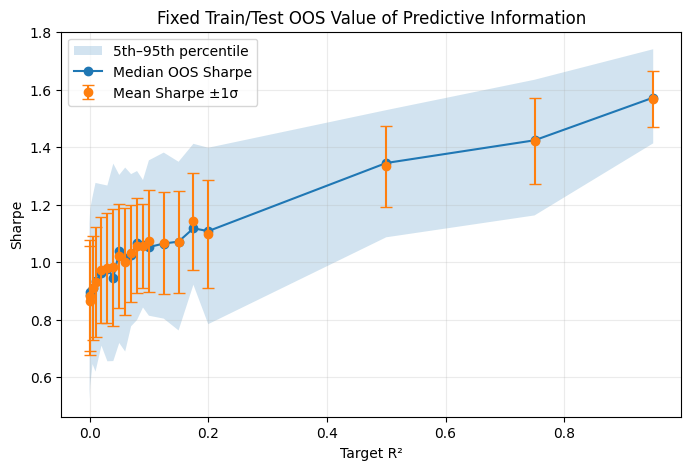

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

x = summary["rsq"].to_numpy()

median = summary["median_sharpe"].to_numpy()
mean = summary["mean_sharpe"].to_numpy()
sigma = summary["sharpe_std"].to_numpy()

p05 = summary["sharpe_p05"].to_numpy()
p95 = summary["sharpe_p95"].to_numpy()


# --------------------------------------------------
# 5th–95th percentile band
# --------------------------------------------------
ax.fill_between(
    x,
    p05,
    p95,
    alpha=0.20,
    label="5th–95th percentile",
)


# --------------------------------------------------
# Median Sharpe line
# --------------------------------------------------
ax.plot(
    x,
    median,
    marker="o",
    label="Median OOS Sharpe",
)


# --------------------------------------------------
# Mean Sharpe with +/- 1 sigma error bars
# --------------------------------------------------
ax.errorbar(
    x,
    mean,
    yerr=sigma,
    fmt="o",
    capsize=4,
    label="Mean Sharpe ±1σ",
)


ax.set_xlabel("Target R²")
ax.set_ylabel("Sharpe")
ax.set_title(
    "Fixed Train/Test OOS Value of Predictive Information"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

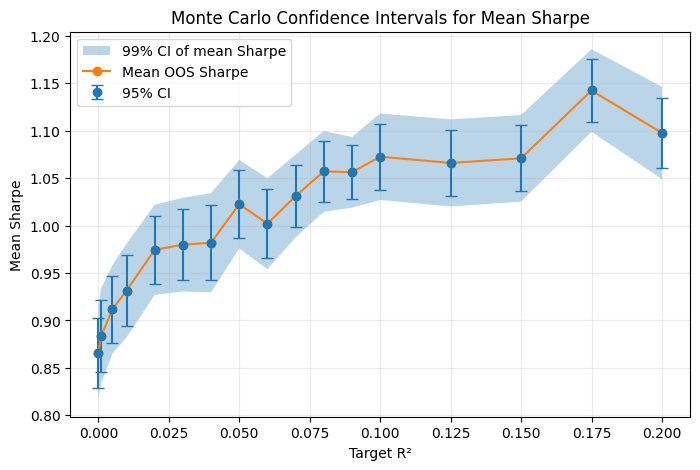

In [48]:
summary["sharpe_se"] = (
    summary["sharpe_std"]
    / np.sqrt(summary["runs"])
)

x = summary["rsq"].to_numpy()
mean = summary["mean_sharpe"].to_numpy()
se = summary["sharpe_se"].to_numpy()


# Approximate normal-theory CIs

ci95_low = mean - 1.96 * se
ci95_high = mean + 1.96 * se

ci99_low = mean - 2.58 * se
ci99_high = mean + 2.58 * se


fig, ax = plt.subplots(figsize=(8, 5))

first_i = 17


ax.errorbar(
    x[:first_i],
    mean[:first_i],
    yerr=1.96 * se[:first_i],
    fmt="o",
    capsize=4,
    label="95% CI",
)


# --------------------------------------------------
# 99% confidence interval
# --------------------------------------------------
ax.fill_between(
    x[:first_i],
    ci99_low[:first_i],
    ci99_high[:first_i],
    alpha=0.30,
    label="99% CI of mean Sharpe",
)


# --------------------------------------------------
# Mean Sharpe
# --------------------------------------------------



ax.plot(
    x[:first_i],
    mean[:first_i],
    marker="o",
    label="Mean OOS Sharpe",
)


ax.set_xlabel("Target R²")
ax.set_ylabel("Mean Sharpe")
ax.set_title(
    "Monte Carlo Confidence Intervals for Mean Sharpe"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

## 21. Save results

In [23]:
equity_dir = paths.output_dir / "equity_curves"
equity_dir.mkdir(parents=True, exist_ok=True)

for rsq in cfg.rsq_values:

    curves = pd.concat(
        equity_curves[rsq],
        axis=1,
    )

    # Normalize each run to start at 1
    curves = curves / curves.iloc[0]

    curves.to_csv(
        equity_dir / f"equity_curves_rsq_{rsq:.4f}.csv"
    )

print(f"Saved equity curves to: {equity_dir.resolve()}")

results_by_run.to_csv(
    paths.output_dir / "train_test_summary_by_run.csv",
    index=False,
)

summary.to_csv(
    paths.output_dir / "train_test_summary_aggregate.csv",
    index=False,
)

fixed_stats.to_csv(
    paths.output_dir / "train_test_fixed_regime_benchmarks.csv",
)

print(f"Saved outputs to {paths.output_dir.resolve()}")

Saved equity curves to: S:\Stratosphere\2026\strategy_economics\Tests_v2_TrainTest\equity_curves
Saved outputs to S:\Stratosphere\2026\strategy_economics\Tests_v2_TrainTest


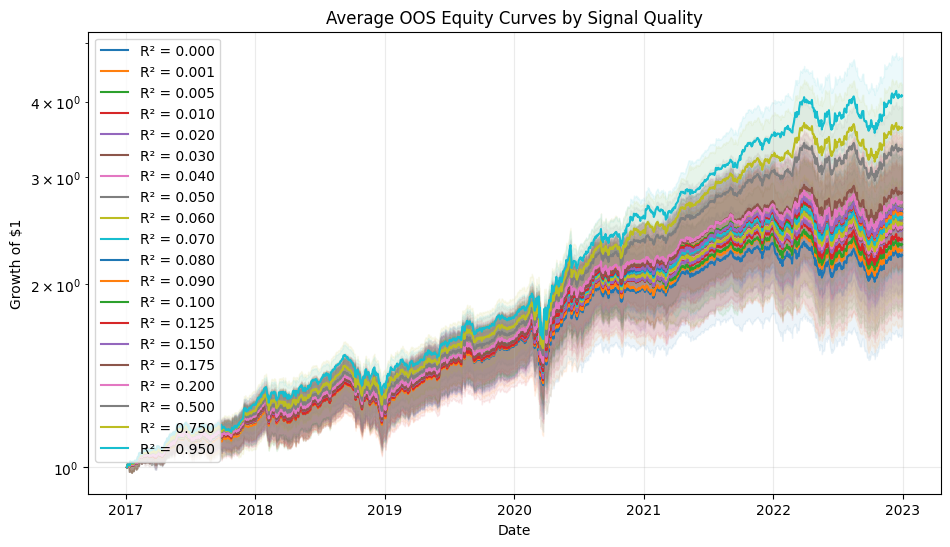

In [24]:
fig, ax = plt.subplots(figsize=(11, 6))

for rsq in cfg.rsq_values:

    curves = pd.concat(
        equity_curves[rsq],
        axis=1,
    )

    curves = curves / curves.iloc[0]

    mean_curve = curves.mean(axis=1)

    p05 = curves.quantile(
        0.05,
        axis=1,
    )

    p95 = curves.quantile(
        0.95,
        axis=1,
    )


    # Mean equity path
    line = ax.plot(
        mean_curve.index,
        mean_curve,
        label=f"R² = {rsq:.3f}",
    )[0]


    # Use same line color for its percentile band
    ax.fill_between(
        mean_curve.index,
        p05,
        p95,
        alpha=0.08,
        color=line.get_color(),
    )


ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.set_yscale('log')
ax.set_title(
    "Average OOS Equity Curves by Signal Quality"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

In [25]:
def process_equity_curves():

    results = pd.DataFrame()
    results.index = equity_curves[cfg.rsq_values[0]][0].index

    for rsq in cfg.rsq_values:

        curves = pd.concat(
            equity_curves[rsq],
            axis=1,
        )

        curves = curves / curves.iloc[0]
        yearly_returns = curves.pct_change(periods=252)
        yearly_returns.dropna(inplace=True)
        yearly_returns[f'Mean_{rsq}'] = yearly_returns.mean(axis=1)
        yearly_returns[f'SE_{rsq}'] = yearly_returns.sem(axis=1)
        results = pd.merge(results, yearly_returns[[f'Mean_{rsq}', f'SE_{rsq}']], left_index=True, right_index=True)

    return results

In [26]:
mean_equity_curves = process_equity_curves()

In [27]:
def plot_return_differential(
    mean_equity_curves: pd.DataFrame,
    compare_rsq: float,
    benchmark_rsq: float = 0,
    export: bool = False,
):
    rsqs = [benchmark_rsq, compare_rsq]

    mean_names = [f"Mean_{rsq}" for rsq in rsqs]
    se_names = [f"SE_{rsq}" for rsq in rsqs]

    relevant_cols = mean_equity_curves[mean_names + se_names].copy()

    # Point estimate of the return differential
    relevant_cols["Differential (point)"] = (
        relevant_cols[f"Mean_{compare_rsq}"]
        - relevant_cols[f"Mean_{benchmark_rsq}"]
    )

    # SE of the differential
    relevant_cols["Differential (SE)"] = np.sqrt(
        relevant_cols[f"SE_{compare_rsq}"] ** 2
        + relevant_cols[f"SE_{benchmark_rsq}"] ** 2
    )

    # 95% confidence interval
    z = 1.96
    relevant_cols["Differential (lower)"] = (
        relevant_cols["Differential (point)"]
        - z * relevant_cols["Differential (SE)"]
    )
    relevant_cols["Differential (upper)"] = (
        relevant_cols["Differential (point)"]
        + z * relevant_cols["Differential (SE)"]
    )

    # Plot
    x = relevant_cols.index

    plt.plot(
        x,
        relevant_cols["Differential (point)"],
        label="Return differential",
    )

    plt.fill_between(
        x,
        relevant_cols["Differential (lower)"],
        relevant_cols["Differential (upper)"],
        alpha=0.2,
        label="95% CI",
    )

    plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
    plt.ylabel('Return Differential')
    plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
    plt.legend()
    plt.title(f'Return Differential - rsq = {compare_rsq}')
    plt.show()

    if export:
        relevant_cols.to_csv(        
            equity_dir / f"reutrn_diff_{compare_rsq:.4f}.csv"
    )

    return relevant_cols

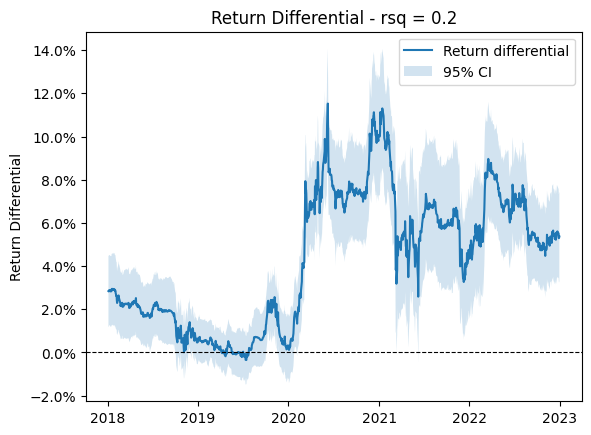

,Mean_0,Mean_0.2,SE_0,SE_0.2,Differential (point),Differential (SE),Differential (lower),Differential (upper)
Date,,,,,,,,
2018-01-04,0.194548,0.222958,0.005566,0.006299,0.028410,0.008406,0.011935,0.044884
2018-01-05,0.195901,0.224189,0.005540,0.006302,0.028288,0.008391,0.011842,0.044733
2018-01-08,0.193385,0.222304,0.005419,0.006275,0.028919,0.008291,0.012669,0.045170
2018-01-09,0.203021,0.231870,0.005404,0.006291,0.028849,0.008293,0.012594,0.045103
2018-01-10,0.203188,0.232012,0.005347,0.006294,0.028824,0.008258,0.012637,0.045010
...,...,...,...,...,...,...,...,...
2022-12-23,-0.034657,0.021290,0.006623,0.008404,0.055947,0.010700,0.034975,0.076919
2022-12-27,-0.043724,0.011286,0.006510,0.008282,0.055010,0.010535,0.034362,0.075658
2022-12-28,-0.048718,0.004206,0.006445,0.008140,0.052924,0.010382,0.032575,0.073273


In [28]:
plot_return_differential(
    mean_equity_curves,
    compare_rsq = 0.2,
    export=True
)

FeeConfig(starting_aum=100000, management_fee_rate=0.02, performance_fee_rate=0.2, hurdle_rate=0.05, hurdle_type='hard', high_water_mark=True, crystallization_frequency='annual', management_fee_basis='daily_nav', day_count=252)
<class 'dict'>
dict_keys([0, 0.001, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.125, 0.15, 0.175, 0.2, 0.5, 0.75, 0.95])


,rsq,runs,mean_management_fees,median_management_fees,mean_performance_fees,median_performance_fees,mean_total_fees,median_total_fees,total_fees_p05,total_fees_p95,mean_marginal_total_fees,median_marginal_total_fees,marginal_total_fees_p05,marginal_total_fees_p95,mean_marginal_management_fees,mean_marginal_performance_fees
0,0.000,100,17531.240823,17717.039638,16242.436211,16922.962333,33773.677035,34500.987643,23147.390613,41832.231849,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.001,100,17720.632532,17566.271211,17206.230842,16948.307818,34926.863374,34274.310634,25303.670326,45178.953724,1153.186339,2017.600987,-12413.561725,12026.505379,189.391709,963.794631
2,0.005,100,17887.571035,17877.038586,17453.739225,17391.321397,35341.310259,35468.158390,26560.113723,45036.190476,1567.633225,805.276442,-10107.494845,14698.888667,356.330212,1211.303013
3,0.010,100,17992.470436,18089.032969,18234.761190,17779.284522,36227.231626,35733.781268,25999.898852,47323.538490,2453.554591,2899.935705,-10171.850352,16183.996468,461.229612,1992.324979
4,0.020,100,18151.760334,18114.888209,18765.077068,18271.391806,36916.837402,36166.436634,28140.744599,48747.423842,3143.160368,1940.296023,-9342.580565,16135.799720,620.519511,2522.640857
5,0.030,100,18290.397435,18227.067691,19437.442676,19390.290595,37727.840110,37973.719247,26961.282765,49147.014927,3954.163076,2753.115284,-9071.978709,19090.971085,759.156611,3195.006465
6,0.040,100,18289.339585,18300.897462,19228.122001,18099.469264,37517.461586,36474.916511,26805.895642,50499.982025,3743.784551,2769.860218,-10905.684899,21859.977365,758.098762,2985.685789
7,0.050,100,18419.998207,18380.307796,20134.051853,19678.741917,38554.050060,38084.436522,28272.266096,48671.377730,4780.373025,4530.506381,-7906.577576,17869.435182,888.757384,3891.615642
8,0.060,100,18302.178276,18398.914010,19365.882776,19299.859193,37668.061052,37947.619581,27936.286067,48181.457757,3894.384018,2003.120720,-8253.433328,19044.447855,770.937453,3123.446565
9,0.070,100,18478.165761,18544.338807,20388.634065,19855.896884,38866.799826,38664.859241,30067.507553,48555.857293,5093.122791,5898.608716,-9653.349275,17863.187763,946.924938,4146.197854


Saved fee outputs to: S:\Stratosphere\2026\strategy_economics\Tests_v2_TrainTest


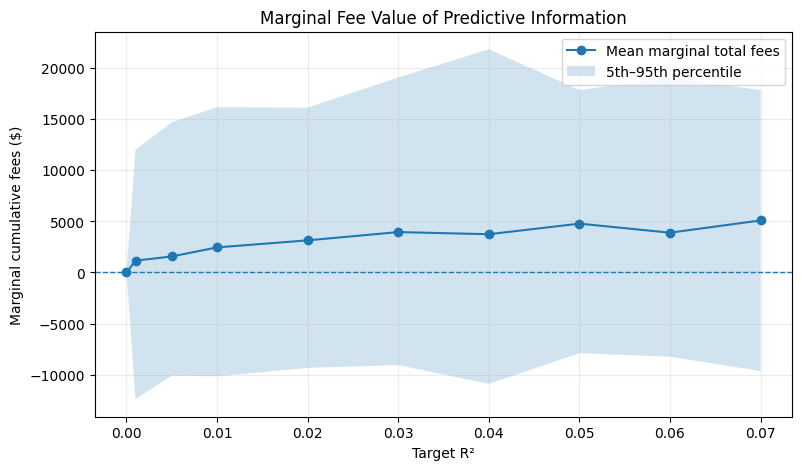

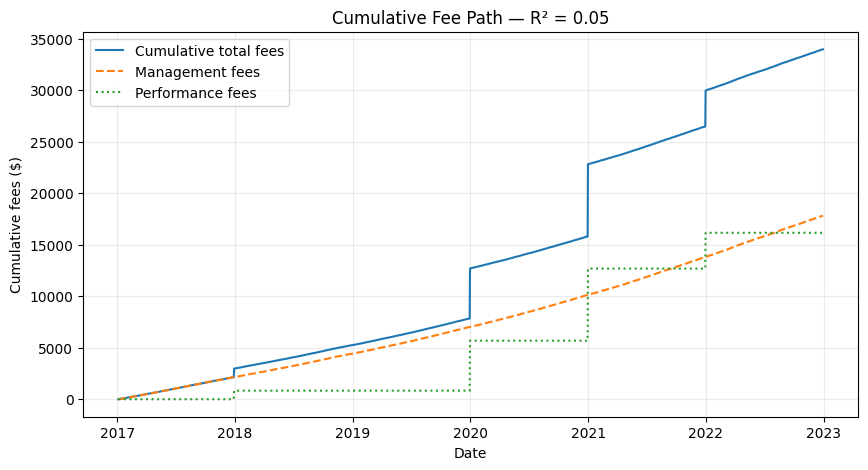

In [35]:
from lib.fees import (
    FeeConfig,
    apply_fees_to_monte_carlo,
    aggregate_fee_economics,
)

# ============================================================
# 1. Fee assumptions
# ============================================================

fee_cfg = FeeConfig(
    starting_aum=100_000,          # $100mm
    management_fee_rate=0.02,          # 2%
    performance_fee_rate=0.20,         # 20%
    hurdle_rate=0.05,                  # 5%

    hurdle_type="hard",                # fee only on return above hurdle
    high_water_mark=True,

    crystallization_frequency="annual",
    management_fee_basis="daily_nav",

    day_count=252,
)

print(fee_cfg)

#First i rsq values
i = 10


# ============================================================
# 2. Apply fees to every Monte Carlo equity curve
#
# equity_curves should already look like:
#
# {
#     0.00: [run_1_series, run_2_series, ...],
#     0.01: [run_1_series, run_2_series, ...],
#     ...
# }
# ============================================================

fee_path_summary, fee_paths_by_rsq = apply_fees_to_monte_carlo(
    equity_curves=equity_curves,
    config=fee_cfg,
    baseline_rsq=0.0,
)

print(type(fee_paths_by_rsq))
print(fee_paths_by_rsq.keys())


# ============================================================
# 3. Aggregate economics by R²
# ============================================================

fee_summary = aggregate_fee_economics(
    fee_path_summary
)

display(fee_summary)


# ============================================================
# 4. Save outputs
# ============================================================

fee_path_summary.to_csv(
    paths.output_dir / "fee_economics_by_run.csv",
    index=False,
)

fee_summary.to_csv(
    paths.output_dir / "fee_economics_summary.csv",
    index=False,
)

print(
    "Saved fee outputs to:",
    paths.output_dir.resolve()
)


# ============================================================
# 5. Plot expected marginal total fees vs R²
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    fee_summary["rsq"][:i],
    fee_summary["mean_marginal_total_fees"][:i],
    marker="o",
    label="Mean marginal total fees",
)

ax.fill_between(
    fee_summary["rsq"][:i],
    fee_summary["marginal_total_fees_p05"][:i],
    fee_summary["marginal_total_fees_p95"][:i],
    alpha=0.20,
    label="5th–95th percentile",
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("Target R²")
ax.set_ylabel("Marginal cumulative fees ($)")
ax.set_title(
    "Marginal Fee Value of Predictive Information"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()


# ============================================================
# 6. Example cumulative-fee path for one R² bucket
# ============================================================

example_rsq = 0.05
example_run = 0   # zero-based list index

example_fee_path = fee_paths_by_rsq[
    example_rsq
][example_run]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    example_fee_path.index,
    example_fee_path["CumulativeTotalFee"],
    label="Cumulative total fees",
)

ax.plot(
    example_fee_path.index,
    example_fee_path["CumulativeManagementFee"],
    linestyle="--",
    label="Management fees",
)

ax.plot(
    example_fee_path.index,
    example_fee_path["CumulativePerformanceFee"],
    linestyle=":",
    label="Performance fees",
)

ax.set_xlabel("Date")
ax.set_ylabel("Cumulative fees ($)")
ax.set_title(
    f"Cumulative Fee Path — R² = {example_rsq:.2f}"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

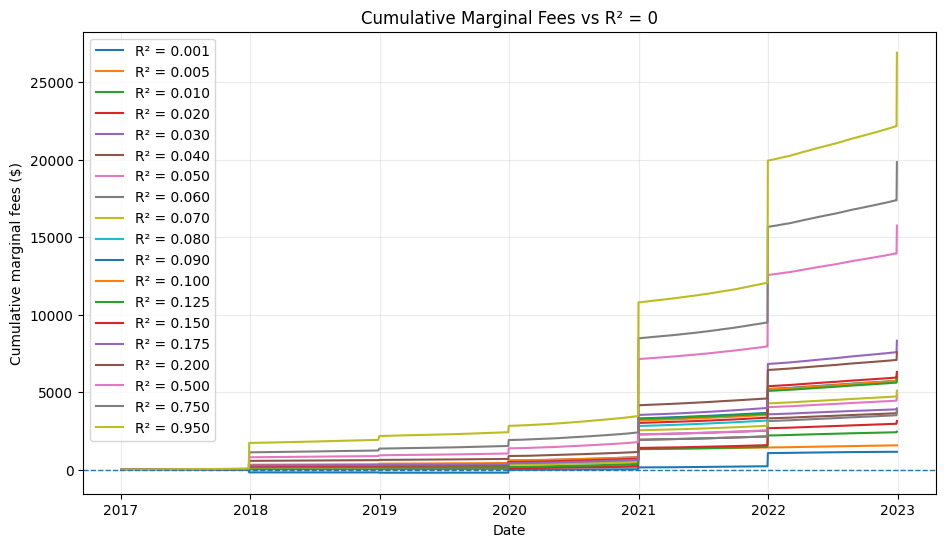

In [36]:
# ============================================================
# MARGINAL FEE TIME SERIES
# ============================================================

baseline_rsq = 0.0

marginal_fee_paths = {}

baseline_paths = fee_paths_by_rsq[baseline_rsq]


for rsq, paths_ in fee_paths_by_rsq.items():

    marginal_fee_paths[rsq] = []

    for run_idx, fee_path in enumerate(paths_):

        baseline_path = baseline_paths[run_idx]

        aligned = pd.concat(
            [
                fee_path[
                    "CumulativeTotalFee"
                ].rename("strategy"),

                baseline_path[
                    "CumulativeTotalFee"
                ].rename("baseline"),
            ],
            axis=1,
            join="inner",
        ).dropna()

        marginal = (
            aligned["strategy"]
            - aligned["baseline"]
        )

        marginal.name = f"run_{run_idx + 1}"

        marginal_fee_paths[rsq].append(
            marginal
        )


# ============================================================
# SUMMARY TIME SERIES
# ============================================================

marginal_fee_ts = {}

for rsq, paths_ in marginal_fee_paths.items():

    curves = pd.concat(
        paths_,
        axis=1,
    )

    marginal_fee_ts[rsq] = pd.DataFrame(
        {
            "Mean": curves.mean(axis=1),

            "Median": curves.median(axis=1),

            "SE": (
                curves.std(axis=1, ddof=1)
                / np.sqrt(curves.shape[1])
            ),

            "P05": curves.quantile(
                0.05,
                axis=1,
            ),

            "P95": curves.quantile(
                0.95,
                axis=1,
            ),
        }
    )


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

for rsq in cfg.rsq_values:

    if rsq == 0:
        continue

    ts = marginal_fee_ts[rsq]

    ax.plot(
        ts.index,
        ts["Mean"],
        label=f"R² = {rsq:.3f}",
    )


ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("Date")
ax.set_ylabel("Cumulative marginal fees ($)")
ax.set_title(
    "Cumulative Marginal Fees vs R² = 0"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

## Interpretation

This version is less adaptive than monthly walk-forward optimization, but it preserves the important OOS boundary:

\[
\text{2011--2016 portfolio selection}
\rightarrow
\text{2017--2023 strategy evaluation}.
\]

Because the three portfolios are frozen, changes across \(R^2\) are especially easy to attribute to the timing information itself rather than to changes in stock selection.

The remaining known contamination is the use of static factor exposures.

## Fast NPV / IRR scenario engine

This cell caches marginal fee cash flows once. After that, you can change **INITIAL_AUM**, **SIGNAL_COST**, or **DISCOUNT_RATE** without rerunning the fee engine. NPV uses exact daily fee timing; IRR uses year-end aggregated marginal fees for much faster scenario iteration.


In [37]:
INITIAL_AUM = 100_000       # scenario AUM ($); does NOT rerun the fee engine
SIGNAL_COST = 2_000         # upfront research / data / signal cost ($)
DISCOUNT_RATE = 0.16        # annual effective discount rate
BASELINE_RSQ = 0.0          # no-information benchmark

# The fee engine was originally run using fee_cfg.starting_aum.
# Because all current fees are percentage-based, fee cash flows scale
# linearly with AUM, so INITIAL_AUM can be changed without rerunning fees.
BASE_FEE_AUM = float(fee_cfg.starting_aum)

# NPV below uses the exact daily fee timing.
# IRR is calculated from fee cash flows aggregated to year-end.
# This is dramatically faster and is also a natural project-finance view.
IRR_CASHFLOW_FREQ = "YE"

In [38]:
import numpy as np
import pandas as pd
from scipy.optimize import brentq


# ============================================================
# FAST NPV / IRR CONFIG
# ============================================================


# ============================================================
# ONE-TIME CACHE OF MARGINAL FEE CASH FLOWS
#
# This expensive alignment / date work is only rebuilt if the underlying
# fee_paths_by_rsq object, baseline R², or base fee AUM changes.
# Merely changing INITIAL_AUM, SIGNAL_COST, or DISCOUNT_RATE reuses it.
# ============================================================

_cache_signature = (
    id(fee_paths_by_rsq),
    float(BASELINE_RSQ),
    float(BASE_FEE_AUM),
    str(IRR_CASHFLOW_FREQ),
)

if globals().get("_marginal_fee_cache_signature") != _cache_signature:

    print("Building marginal-fee valuation cache once...")

    marginal_fee_valuation_cache = {}
    baseline_paths = fee_paths_by_rsq[BASELINE_RSQ]

    for rsq, paths_ in fee_paths_by_rsq.items():

        if np.isclose(rsq, BASELINE_RSQ):
            continue

        daily_runs = []
        irr_runs = []
        common_daily_years = None
        common_irr_years = None

        for run_idx, strategy in enumerate(paths_):

            baseline = baseline_paths[run_idx]

            # Fast path: expected case, same dates.
            if strategy.index.equals(baseline.index):

                dates = pd.DatetimeIndex(strategy.index)

                marginal = pd.Series(
                    strategy["TotalFee"].to_numpy(dtype=float)
                    - baseline["TotalFee"].to_numpy(dtype=float),
                    index=dates,
                    name="MarginalFee",
                )

            # Safe fallback if the two paths are not perfectly aligned.
            else:

                aligned = pd.concat(
                    [
                        strategy["TotalFee"].rename("strategy"),
                        baseline["TotalFee"].rename("baseline"),
                    ],
                    axis=1,
                    join="inner",
                ).fillna(0.0)

                marginal = (
                    aligned["strategy"] - aligned["baseline"]
                ).rename("MarginalFee")

                dates = pd.DatetimeIndex(marginal.index)

            marginal = marginal.sort_index()

            # ------------------------------------------------
            # Exact daily timing for NPV
            # ------------------------------------------------

            t0 = marginal.index[0] - pd.Timedelta(days=1)

            daily_years = (
                (marginal.index - t0).days.to_numpy(dtype=float)
                / 365.0
            )

            daily_values = marginal.to_numpy(dtype=float)

            if common_daily_years is None:
                common_daily_years = daily_years
            elif not np.array_equal(common_daily_years, daily_years):
                raise ValueError(
                    f"Daily fee dates differ across Monte Carlo runs for R²={rsq}. "
                    "The fast matrix cache assumes a common date grid."
                )

            daily_runs.append(daily_values)

            # ------------------------------------------------
            # Year-end aggregation for fast IRR
            # ------------------------------------------------

            annual_cf = marginal.resample(IRR_CASHFLOW_FREQ).sum()

            irr_years = (
                (annual_cf.index - t0).days.to_numpy(dtype=float)
                / 365.0
            )

            irr_values = annual_cf.to_numpy(dtype=float)

            if common_irr_years is None:
                common_irr_years = irr_years
            elif not np.array_equal(common_irr_years, irr_years):
                raise ValueError(
                    f"IRR cash-flow dates differ across Monte Carlo runs for R²={rsq}."
                )

            irr_runs.append(irr_values)

        marginal_fee_valuation_cache[float(rsq)] = {
            "daily_years": common_daily_years,
            "daily_fees": np.vstack(daily_runs),
            "irr_years": common_irr_years,
            "irr_fees": np.vstack(irr_runs),
        }

    _marginal_fee_cache_signature = _cache_signature

    # Underlying fee paths changed, so any old IRRs are stale.
    _project_irr_cache = {}

    print("Marginal-fee valuation cache built.")

else:

    print("Reusing cached marginal-fee cash flows.")


# ============================================================
# FAST HELPERS
# ============================================================

def fast_xirr(years, fees, signal_cost):
    """
    XIRR-style project IRR using already-prepared numeric arrays.

    Initial signal cost occurs at t=0.
    Future marginal fees occur at the supplied year fractions.
    """

    years = np.asarray(years, dtype=float)
    fees = np.asarray(fees, dtype=float)

    if signal_cost <= 0:
        return np.nan

    if not np.any(fees > 0):
        return np.nan

    def project_npv(rate):
        return (
            -signal_cost
            + np.sum(fees / (1.0 + rate) ** years)
        )

    lower = -0.9999
    upper = 1.0

    f_low = project_npv(lower)
    f_high = project_npv(upper)

    # Expand upper bracket only when necessary.
    attempts = 0

    while (
        np.isfinite(f_low)
        and np.isfinite(f_high)
        and np.sign(f_low) == np.sign(f_high)
        and attempts < 30
    ):
        upper *= 2.0
        f_high = project_npv(upper)
        attempts += 1

    if (
        not np.isfinite(f_low)
        or not np.isfinite(f_high)
        or np.sign(f_low) == np.sign(f_high)
    ):
        return np.nan

    try:
        return brentq(
            project_npv,
            lower,
            upper,
            xtol=1e-10,
            rtol=1e-10,
            maxiter=100,
        )
    except ValueError:
        return np.nan


# Preserve IRRs across reruns when only DISCOUNT_RATE changes.
if "_project_irr_cache" not in globals():
    _project_irr_cache = {}


# ============================================================
# FAST SCENARIO ANALYSIS
# ============================================================

aum_scale = float(INITIAL_AUM) / BASE_FEE_AUM

rows = []

for rsq, cached in marginal_fee_valuation_cache.items():

    daily_years = cached["daily_years"]
    daily_fees = cached["daily_fees"] * aum_scale

    irr_years = cached["irr_years"]
    irr_fees = cached["irr_fees"] * aum_scale

    # --------------------------------------------------------
    # Vectorized exact-daily NPV for EVERY run at this R²
    # --------------------------------------------------------

    discount_factors = (1.0 + DISCOUNT_RATE) ** daily_years

    pv_marginal_fees = (
        daily_fees / discount_factors[None, :]
    ).sum(axis=1)

    project_npv = pv_marginal_fees - SIGNAL_COST
    cumulative_marginal_fees = daily_fees.sum(axis=1)

    # --------------------------------------------------------
    # IRR
    #
    # IRR does NOT depend on DISCOUNT_RATE, so cache by
    # R², run, AUM, and signal cost.
    # --------------------------------------------------------

    project_irrs = np.empty(daily_fees.shape[0], dtype=float)

    for run_idx in range(daily_fees.shape[0]):

        irr_key = (
            float(rsq),
            int(run_idx),
            float(INITIAL_AUM),
            float(SIGNAL_COST),
            str(IRR_CASHFLOW_FREQ),
        )

        if irr_key not in _project_irr_cache:

            _project_irr_cache[irr_key] = fast_xirr(
                years=irr_years,
                fees=irr_fees[run_idx],
                signal_cost=SIGNAL_COST,
            )

        project_irrs[run_idx] = _project_irr_cache[irr_key]

    # --------------------------------------------------------
    # Store run-level results
    # --------------------------------------------------------

    for run_idx in range(daily_fees.shape[0]):

        rows.append(
            {
                "rsq": rsq,
                "run": run_idx + 1,
                "initial_aum": INITIAL_AUM,
                "signal_cost": SIGNAL_COST,
                "discount_rate": DISCOUNT_RATE,
                "pv_marginal_fees": pv_marginal_fees[run_idx],
                "project_npv": project_npv[run_idx],
                "project_irr": project_irrs[run_idx],
                "cumulative_marginal_fees": cumulative_marginal_fees[run_idx],
                "positive_npv": project_npv[run_idx] > 0,
            }
        )


investment_results = pd.DataFrame(rows)


# ============================================================
# SUMMARY BY R²
# ============================================================

investment_summary = (
    investment_results
    .groupby("rsq", as_index=False)
    .agg(
        runs=("run", "count"),

        mean_pv_marginal_fees=("pv_marginal_fees", "mean"),
        median_pv_marginal_fees=("pv_marginal_fees", "median"),
        pv_marginal_fees_p05=(
            "pv_marginal_fees",
            lambda x: x.quantile(0.05),
        ),
        pv_marginal_fees_p95=(
            "pv_marginal_fees",
            lambda x: x.quantile(0.95),
        ),

        mean_project_npv=("project_npv", "mean"),
        median_project_npv=("project_npv", "median"),
        project_npv_p05=(
            "project_npv",
            lambda x: x.quantile(0.05),
        ),
        project_npv_p95=(
            "project_npv",
            lambda x: x.quantile(0.95),
        ),

        median_project_irr=("project_irr", "median"),
        project_irr_p05=(
            "project_irr",
            lambda x: x.dropna().quantile(0.05),
        ),
        project_irr_p95=(
            "project_irr",
            lambda x: x.dropna().quantile(0.95),
        ),

        probability_positive_npv=(
            "positive_npv",
            "mean",
        ),
    )
)


# ============================================================
# DISPLAY
# ============================================================

print(f"Scenario AUM: ${INITIAL_AUM:,.0f}")
print(f"Base fee-engine AUM: ${BASE_FEE_AUM:,.0f}")
print(f"Signal cost: ${SIGNAL_COST:,.0f}")
print(f"Discount rate: {DISCOUNT_RATE:.1%}")
print(f"Baseline R²: {BASELINE_RSQ}")
print(f"IRR cash-flow aggregation: {IRR_CASHFLOW_FREQ}")
print(
    "Note: NPV uses exact daily fee timing; "
    "IRR uses year-end aggregated marginal fees."
)

display(investment_summary)


Building marginal-fee valuation cache once...
Marginal-fee valuation cache built.
Scenario AUM: $100,000
Base fee-engine AUM: $100,000
Signal cost: $2,000
Discount rate: 16.0%
Baseline R²: 0.0
IRR cash-flow aggregation: YE
Note: NPV uses exact daily fee timing; IRR uses year-end aggregated marginal fees.


,rsq,runs,mean_pv_marginal_fees,median_pv_marginal_fees,pv_marginal_fees_p05,pv_marginal_fees_p95,mean_project_npv,median_project_npv,project_npv_p05,project_npv_p95,median_project_irr,project_irr_p05,project_irr_p95,probability_positive_npv
0,0.001,100,520.078745,628.425397,-6906.504748,6488.139810,-1479.921255,-1371.574603,-8906.504748,4488.139810,0.275181,-0.323484,1.028301,0.36
1,0.005,100,915.454936,619.387343,-5121.260013,8029.034029,-1084.545064,-1380.612657,-7121.260013,6029.034029,0.327584,-0.898381,0.833739,0.40
2,0.010,100,1290.511554,1230.853098,-5622.341920,8381.388455,-709.488446,-769.146902,-7622.341920,6381.388455,0.368569,-0.433271,1.036475,0.45
3,0.020,100,1628.413771,1018.311331,-5065.770654,7963.883717,-371.586229,-981.688669,-7065.770654,5963.883717,0.230679,-0.955304,1.086683,0.42
4,0.030,100,2148.356117,1302.602072,-5468.555468,10052.285827,148.356117,-697.397928,-7468.555468,8052.285827,0.429545,-0.753295,1.182573,0.47
5,0.040,100,1994.083770,1622.752059,-5656.632080,11460.799267,-5.916230,-377.247941,-7656.632080,9460.799267,0.323798,-0.744171,1.069161,0.48
6,0.050,100,2512.003642,2496.409727,-5191.647360,10464.017487,512.003642,496.409727,-7191.647360,8464.017487,0.401219,-0.815925,0.931841,0.53
7,0.060,100,2050.746564,1517.879821,-4734.651270,10420.225051,50.746564,-482.120179,-6734.651270,8420.225051,0.285439,-0.943524,1.086376,0.43
8,0.070,100,2659.828724,2907.089174,-5155.686695,9006.351833,659.828724,907.089174,-7155.686695,7006.351833,0.420633,-0.963468,1.074859,0.56
9,0.080,100,3213.200111,3438.868690,-3479.437570,9497.146212,1213.200111,1438.868690,-5479.437570,7497.146212,0.406755,-0.922747,1.039349,0.57


In [39]:
from matplotlib.ticker import FuncFormatter
def accounting_fmt(x, pos):
    if np.isclose(x, 0):
        return "$-"
    elif x < 0:
        return f"(${abs(x):,.0f})"
    else:
        return f"${x:,.0f}"

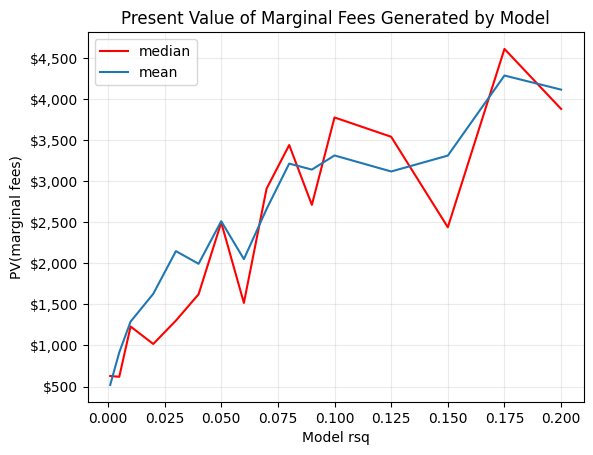

In [43]:
first_i = 16

plt.plot(investment_summary['rsq'][:first_i], investment_summary['median_pv_marginal_fees'][:first_i], 
label='median', color = 'red')
plt.plot(investment_summary['rsq'][:first_i], investment_summary['mean_pv_marginal_fees'][:first_i], label='mean')
plt.xlabel('Model rsq')
plt.ylabel('PV(marginal fees)')
plt.title('Present Value of Marginal Fees Generated by Model')
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(accounting_fmt)
)
plt.grid(alpha=0.25)
plt.legend()
plt.show()